In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering

In [2]:
# 1. Load and clean the dataset
# 1. Загрузка и очистка набора данных
df = pd.read_csv('Econom_Cities_data.csv', sep=';', decimal=',')
df = pd.DataFrame(df)
df

,City,Work,Price,Salary
0,Amsterdam,1714,65.6,49.0
1,Athens,1792,53.8,30.4
2,Bogota,2152,37.9,11.5
3,Bombay,2052,30.3,5.3
4,Brussels,1708,73.8,50.5
5,Buenos_Aires,1971,56.1,12.5
6,Cairo,-9999,37.1,-9999.0
7,Caracas,2041,61.0,10.9
8,Chicago,1924,73.9,61.9
9,Copenhagen,1717,91.3,62.9


In [3]:
# Replace -9999 with NaN and drop missing values
# Замена -9999 на NaN и удаление пропущенных значений
df.replace(-9999, np.nan, inplace=True)
df_clean = df.dropna().copy()
df_clean

,City,Work,Price,Salary
0,Amsterdam,1714.0,65.6,49.0
1,Athens,1792.0,53.8,30.4
2,Bogota,2152.0,37.9,11.5
3,Bombay,2052.0,30.3,5.3
4,Brussels,1708.0,73.8,50.5
5,Buenos_Aires,1971.0,56.1,12.5
7,Caracas,2041.0,61.0,10.9
8,Chicago,1924.0,73.9,61.9
9,Copenhagen,1717.0,91.3,62.9
10,Dublin,1759.0,76.0,41.4


In [4]:
# 2. Select features and standardize the data
# 2. Выбор признаков и стандартизация данных
features = ['Work', 'Price', 'Salary']
X = df_clean[features]

In [5]:
# Standardization is crucial because variables have different scales (thousands vs tens)
# Стандартизация критически важна, так как переменные имеют разные масштабы (тысячи против десятков)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [6]:
# 3. Adjustable Function for Hierarchical Clustering (Linkage Matrix)
# 3. Настраиваемая функция для иерархической кластеризации (Матрица связей)
def perform_hierarchical_clustering(data, method='ward', metric='euclidean'):
    """
    Performs hierarchical clustering and returns the linkage matrix.
    Выполняет иерархическую кластеризацию и возвращает матрицу связей.
    """
    return linkage(data, method=method, metric=metric)

In [7]:
# Generate linkage matrix using Ward's method
# Создание матрицы связей с использованием метода Уорда
Z = perform_hierarchical_clustering(X_scaled, method='ward')

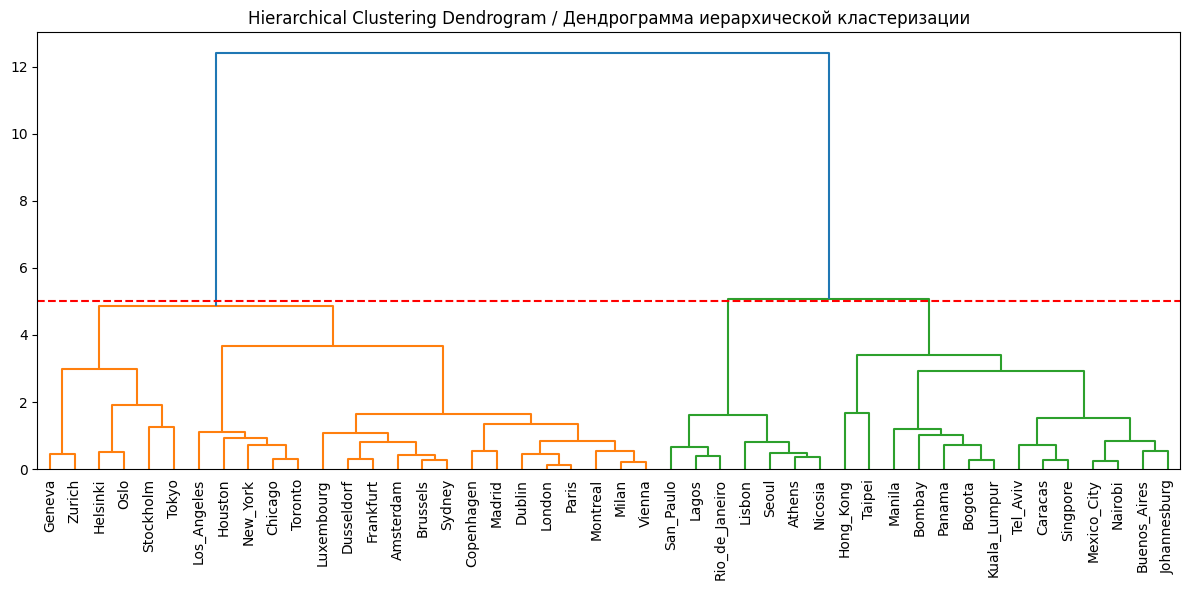

In [8]:
# 4. Visualization: Dendrogram to justify the number of clusters
# 4. Визуализация: Дендрограмма для обоснования количества кластеров
plt.figure(figsize=(12, 6))
plt.title("Hierarchical Clustering Dendrogram / Дендрограмма иерархической кластеризации")
dendrogram(Z, labels=df_clean['City'].values, leaf_rotation=90, leaf_font_size=10)
plt.axhline(y=5, color='r', linestyle='--') # Proposed cut-off line / Предлагаемая линия отсечения
plt.tight_layout()
plt.show()

In [9]:
# 5. Apply Agglomerative Clustering based on dendrogram insight (e.g., 3 clusters)
# 5. Применение агломеративной кластеризации на основе данных дендрограммы (например, 3 кластера)
n_clusters = 3

hc = AgglomerativeClustering(n_clusters=n_clusters, metric='euclidean', linkage='ward')
df_clean['Cluster'] = hc.fit_predict(X_scaled)

In [10]:
# 6. Interpretation: Calculate mean values for each cluster
# 6. Интерпретация: Вычисление средних значений для каждого кластера
cluster_summary = df_clean.groupby('Cluster')[features].mean()
print("Cluster Profiles (Mean Values) / Профили кластеров (Средние значения):")
print(cluster_summary)

Cluster Profiles (Mean Values) / Профили кластеров (Средние значения):
                Work      Price     Salary
Cluster                                   
0        1789.240000  84.972000  59.032000
1        2082.357143  53.121429  14.914286
2        1798.857143  50.942857  19.214286


In [11]:
for c in range(3):
    cities = df_clean[df_clean['Cluster'] == c]['City'].tolist()
    print(f"Cluster {c}: {', '.join(cities)}")

Cluster 0: Amsterdam, Brussels, Chicago, Copenhagen, Dublin, Dusseldorf, Frankfurt, Geneva, Helsinki, Houston, London, Los_Angeles, Luxembourg, Madrid, Milan, Montreal, New_York, Oslo, Paris, Stockholm, Sydney, Tokyo, Toronto, Vienna, Zurich
Cluster 1: Bogota, Bombay, Buenos_Aires, Caracas, Hong_Kong, Johannesburg, Kuala_Lumpur, Manila, Mexico_City, Nairobi, Panama, Singpore, Taipei, Tel_Aviv
Cluster 2: Athens, Lagos, Lisbon, Nicosia, Rio_de_Janeiro, San_Paulo, Seoul
